In [1]:
import kagglehub

kagglehub.login()


In [2]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('cifar-10')

print("Path to competition files:", path)

Path to competition files: C:\Users\Rushabh\.cache\kagglehub\competitions\cifar-10


In [3]:
import os

dataset_path = r"C:\Users\Rushabh\.cache\kagglehub\competitions\cifar-10"

print(os.listdir(dataset_path))

['7-zip.chm', '7-zip.dll', '7-zip32.dll', '7z.dll', '7z.exe', '7z.sfx', '7zCon.sfx', '7zFM.exe', '7zG.exe', 'descript.ion', 'History.txt', 'Lang', 'License.txt', 'readme.txt', 'sampleSubmission.csv', 'test.7z', 'train', 'train.7z', 'trainLabels.csv', 'Uninstall.exe']


In [4]:
import csv

labels_path = os.path.join(dataset_path, 'trainLabels.csv')

with open(labels_path, 'r') as f:
    reader = csv.reader(f)

    for i , row in enumerate(reader):
        if i == 0:continue

        if i == 10:
            break

In [5]:
import pandas as pd 

train_labels = pd.read_csv(labels_path)

print("1", train_labels.head())
print("#" * 50)
print("2", train_labels['label'].value_counts())
print("#" * 50)
print(train_labels['label'].unique())
print("#" * 50)

1    id       label
0   1        frog
1   2       truck
2   3       truck
3   4        deer
4   5  automobile
##################################################
2 label
frog          5000
truck         5000
deer          5000
automobile    5000
bird          5000
horse         5000
ship          5000
cat           5000
dog           5000
airplane      5000
Name: count, dtype: int64
##################################################
['frog' 'truck' 'deer' 'automobile' 'bird' 'horse' 'ship' 'cat' 'dog'
 'airplane']
##################################################


In [6]:
import pandas as pd
import csv

sample_submission_path = os.path.join(dataset_path, 'sampleSubmission.csv')

sample_sub = pd.read_csv(sample_submission_path)

print("1", sample_sub.head())
print("#" * 50)
print("2", sample_sub['label'].value_counts())
print("#" * 50)
print("3", sample_sub['label'].unique())
print("#" * 50)
print(sample_sub.shape)
print("#" * 50)
print("Number of labels in submission file:", sample_sub['label'].count())

1    id label
0   1   cat
1   2   cat
2   3   cat
3   4   cat
4   5   cat
##################################################
2 label
cat    300000
Name: count, dtype: int64
##################################################
3 ['cat']
##################################################
(300000, 2)
##################################################
Number of labels in submission file: 300000


Missing Values Present In the the train_labels 

In [7]:
print(train_labels['label'].isnull().sum())   

print(train_labels['label'].isnull().mean())  
  
print(train_labels['label'].isnull().sum() / len(train_labels))

0
0.0
0.0


In [8]:
unique_values = train_labels["id"].unique()
print("Number of unique values in 'id' column:", len(unique_values))

Number of unique values in 'id' column: 50000


In [9]:
expecred_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

acutal_labels = set(train_labels['label'].unique())

print("Labels matched:", acutal_labels == set(expecred_labels))
print("UnExpected labels:", acutal_labels - set(expecred_labels))
print( "Missing labels:", set(expecred_labels) - acutal_labels)

Labels matched: True
UnExpected labels: set()
Missing labels: set()


In [10]:
print(train_labels.shape)

(50000, 2)


##Meta Data

In [11]:
import pandas as pd

expected_labels = {
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
}

actual_labels = set(train_labels['label'].unique())
class_counts = train_labels['label'].value_counts()

print("=" * 50)
print("       CIFAR-10 METADATA REPORT")
print("=" * 50)

print(f"Total training rows       : {len(train_labels)}")
print(f"Total columns             : {train_labels.shape[1]}")
print(f"Missing IDs               : {train_labels['id'].isnull().sum()}")
print(f"Missing labels            : {train_labels['label'].isnull().sum()}")
print(f"Duplicate IDs             : {train_labels['id'].duplicated().sum()}")
print(f"Unique image IDs          : {train_labels['id'].nunique()}")
print(f"Unique classes            : {train_labels['label'].nunique()}")

print("-" * 50)
print("CLASS DISTRIBUTION")
print("-" * 50)

for label, count in class_counts.sort_index().items():
    print(f"{label:<12}: {count:>6} images")

print("-" * 50)
print(f"Expected classes valid    : {actual_labels == expected_labels}")
print(f"Unexpected classes        : {actual_labels - expected_labels}")
print(f"Missing classes           : {expected_labels - actual_labels}")
print(f"Classes equally balanced  : {class_counts.nunique() == 1}")
print("=" * 50)

       CIFAR-10 METADATA REPORT
Total training rows       : 50000
Total columns             : 2
Missing IDs               : 0
Missing labels            : 0
Duplicate IDs             : 0
Unique image IDs          : 50000
Unique classes            : 10
--------------------------------------------------
CLASS DISTRIBUTION
--------------------------------------------------
airplane    :   5000 images
automobile  :   5000 images
bird        :   5000 images
cat         :   5000 images
deer        :   5000 images
dog         :   5000 images
frog        :   5000 images
horse       :   5000 images
ship        :   5000 images
truck       :   5000 images
--------------------------------------------------
Expected classes valid    : True
Unexpected classes        : set()
Missing classes           : set()
Classes equally balanced  : True


In [12]:
import os
print(os.listdir(dataset_path))
import os

train_image_path = os.path.join(dataset_path, 'train')

print("Number of training images:", len(os.listdir(train_image_path)))


['7-zip.chm', '7-zip.dll', '7-zip32.dll', '7z.dll', '7z.exe', '7z.sfx', '7zCon.sfx', '7zFM.exe', '7zG.exe', 'descript.ion', 'History.txt', 'Lang', 'License.txt', 'readme.txt', 'sampleSubmission.csv', 'test.7z', 'train', 'train.7z', 'trainLabels.csv', 'Uninstall.exe']
Number of training images: 1


In [13]:
import os

train_image_path = os.path.join(dataset_path, 'train','train')

print(len(os.listdir(train_image_path)))

50000


In [14]:
from PIL import Image
img  = Image.open(os.path.join(train_image_path, '1.png'))
img.show()

In [15]:
print(img.size)
print(img.mode)
print(img.format)

(32, 32)
RGB
PNG


In [16]:
from PIL import Image
import os
import pandas as pd
from wcwidth import width

widths = []
heights = []
modes = []

for filename in os.listdir(train_image_path):
    image_path = os.path.join(train_image_path, filename)

    img = Image.open(image_path)

    width ,height = img.size
    widths.append(width)
    heights.append(height)
    modes.append(img.mode)

df = train_labels.copy()
df["width"] = widths
df["height"] = heights
df["mode"] = modes
    


In [17]:
unique_dimensions = df[["width", "height"]].drop_duplicates()

print(unique_dimensions)

print(df.value_counts("mode"))

   width  height
0     32      32
mode
RGB    50000
Name: count, dtype: int64


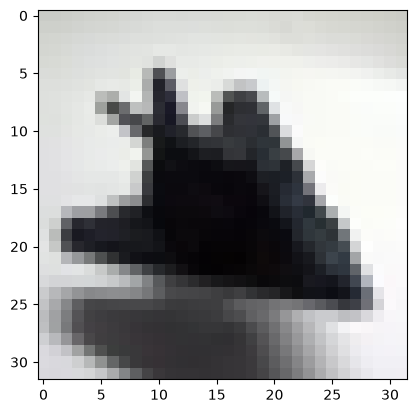

In [18]:
import matplotlib.pyplot as plt


eg_1 = df[df['label'] == 'airplane']  
filename = f"{eg_1['id'].iloc[0]}.png"  
image_path = os.path.join(train_image_path, filename)
img = Image.open(image_path)
plt.imshow(img)


   id       label
0   1        frog
1   2       truck
2   3       truck
3   4        deer
4   5  automobile


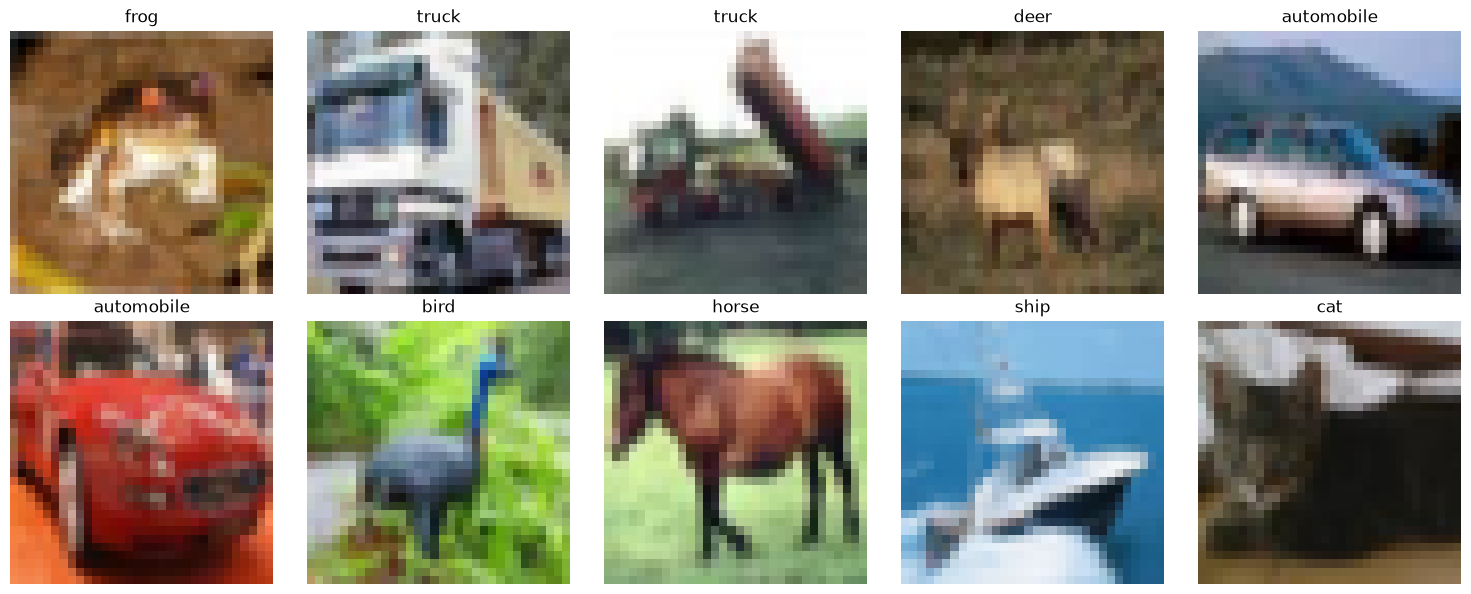

In [19]:
from PIL import Image
import os
import pandas as pd

train_labels = os.path.join(dataset_path, "trainLabels.csv")

df = pd.read_csv(train_labels)

print(df.head())

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

sample_df = df.head(10)

for index , sample in sample_df.iterrows():
    image_id = sample["id"]
    filename = f"{image_id}.png"

    image_path = os.path.join(train_image_path, filename)

    img = Image.open(image_path)

    row = index // 5
    col = index % 5

    
    axes[row, col].imshow(img)
    axes[row, col].set_title(sample["label"])
    axes[row, col].axis("off")

    
plt.tight_layout()
plt.show()


In [20]:
from PIL import Image
import numpy as np
img = Image.open(image_path)

width,height = img.size
total_pixels = width * height

print("Total Pixels: ", total_pixels)

img_num = np.array(img)

print(img_num.shape)

print("Minimum:", img_num.min())
print("Maximum:", img_num.max())
print("Mean:", img_num.mean())


Total Pixels:  1024
(32, 32, 3)
Minimum: 11
Maximum: 218
Mean: 70.49869791666667


In [21]:
import os 
from PIL import Image

pixel_sum = np.zeros(3)
squared_sum = np.zeros(3)
for img in os.listdir(train_image_path):
    image_file = os.path.join(train_image_path, img)
    img = Image.open(image_file)
    img_numA = np.array(img)

    pixel_sum += img_numA.sum(axis=(0,1))
    img_numA = np.array(img).astype(np.float64)
    squared_sum += np.sum(img_numA ** 2, axis = (0,1))

print(pixel_sum)
print(squared_sum)

N = 50000 * 1024
Mean = (pixel_sum) / N

print("The Mean is:",Mean)

std= np.sqrt((squared_sum) / (N) - (Mean * Mean))
print("The Standard Deviation is:", std)

[6.41571420e+09 6.29506018e+09 5.82990762e+09]
[1.00710243e+12 9.71356520e+11 8.91641299e+11]
The Mean is: [125.30691805 122.95039414 113.86538318]
The Standard Deviation is: [62.99321928 62.08870764 66.70489964]


In [22]:
import sklearn

from sklearn.model_selection import train_test_split

X = df["id"]
y = df["label"]

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
    shuffle=True
)

In [23]:
print("The Shape of X_train is: ",X_train.shape)
print("The Shape of X_test is: ",X_test.shape)
print("The Shape of y_train is: ",y_train.shape)
print("The Shape of y_test is: ",y_test.shape)

The Shape of X_train is:  (40000,)
The Shape of X_test is:  (10000,)
The Shape of y_train is:  (40000,)
The Shape of y_test is:  (10000,)


##CONVERTING TO TENSOR

In [24]:
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

In [25]:
img__path  = os.path.join(train_image_path, f"{image_id}.png")
img  = Image.open(img__path).convert("RGB")

In [26]:
from torchvision import transforms
transforms = transforms.ToTensor()
img_transformed = transforms(img)
print(img_transformed.shape)


torch.Size([3, 32, 32])


In [27]:
import os
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.ToTensor()
])

class Cifar10_cnn(Dataset):
    def __init__(self, image_path, label, transform=None):
        super().__init__()
        self.image_path = image_path
        self.label = label
        self.transform = transform

    def __len__(self):
        return len(self.image_path)

    def __getitem__(self, index):
        filename = f"{self.image_path.iloc[index]}.png"
        label = self.label.iloc[index]

        img_path = os.path.join(train_image_path, filename)
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = class_to_idx[label]
        label = torch.tensor(label, dtype=torch.long)

        return img, label

In [28]:
class_to_idx = {
    "airplane": 0,
    "automobile": 1,
    "bird": 2,
    "cat": 3,
    "deer": 4,
    "dog": 5,
    "frog": 6,
    "horse": 7,
    "ship": 8,
    "truck": 9
}

In [29]:
from torchvision import transforms

transform = transforms.ToTensor()

train_data_set = Cifar10_cnn(
    image_path=X_train,
    label=y_train,
    transform=transform
)

test_data_set = Cifar10_cnn(
    image_path=X_test,
    label=y_test,
    transform=transform
)

print("The length of train_data_set:", len(train_data_set))
print("The length of test_data_set:", len(test_data_set))

The length of train_data_set: 40000
The length of test_data_set: 10000


In [30]:
img, label = train_data_set[0]


print("Image type:", type(img))
print("Label:", label)
print("Label type:", type(label))



Image type: <class 'torch.Tensor'>
Label: tensor(6)
Label type: <class 'torch.Tensor'>


In [31]:
import torch
from torch.utils.data import DataLoader
BATCH_SIZE = 32
train_data_loader = DataLoader(
    dataset=train_data_set,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_data_loader = DataLoader(
    dataset=test_data_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [32]:
train_feature, train_lables = next(iter(train_data_loader))

Image size: (32, 32)
Image mode: RGB


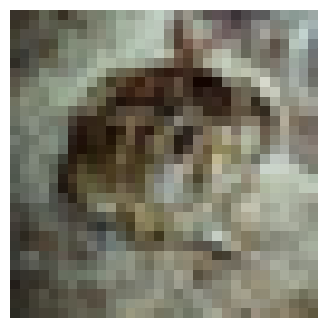

In [33]:
from PIL import Image
import os
import matplotlib.pyplot as plt

filename = f"{X_train.iloc[0]}.png"
img_path = os.path.join(train_image_path, filename)

original_img = Image.open(img_path)

print("Image size:", original_img.size)
print("Image mode:", original_img.mode)

plt.figure(figsize=(4, 4))
plt.imshow(original_img)
plt.axis("off")
plt.show()

Normalization

In [34]:
for filename in X_train:
    filename = f"{filename}.png"
    img_path = os.path.join(train_image_path, filename)

    img = Image.open(img_path).convert("RGB")
    img = image_transform(img)

In [35]:
mean = torch.mean(img, dim = (1,2))
std = torch.std(img, dim = (1,2))
print("Mean:", mean)
print("Standard deviation:", std)

Mean: tensor([0.2892, 0.5442, 0.5703])
Standard deviation: tensor([0.1069, 0.1778, 0.2085])


##We'll move from single-image statistics to dataset-wide statistics using iteration.
converts each image from a PIL Image into a PyTorch tensor.

In [36]:
from PIL import Image
import os


for img in X_train:

    img =Image.open(image_path).convert("RGB")
    img = image_transform(img)

print("The shape of the of image:", img.shape)
print("The datatype of the image:", img.dtype)

The shape of the of image: torch.Size([3, 32, 32])
The datatype of the image: torch.float32


In [37]:
import os
from PIL import Image
import torch

sum_RGB = torch.zeros(3, dtype= torch.float32)
sum_squ_RGB = torch.zeros(3, dtype= torch.float32)
total_pixels = 0

for i, filename in enumerate(X_train):

    img_path = os.path.join(train_image_path, f"{filename}.png")

    img = Image.open(img_path).convert("RGB")
    img = image_transform(img)

    sum_RGB += torch.sum(img, dim = (1,2))

    sum_squ_RGB += torch.sum(img ** 2, dim = (1,2))

    total_pixels += img.shape[1] * img.shape[2]

    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1}/{len(X_train)} images")
RGB_mean = sum_RGB / total_pixels
variance_RGB = (sum_squ_RGB / total_pixels) - (RGB_mean ** 2)
std_RGB = torch.sqrt(variance_RGB)

print("RGB Mean:", RGB_mean)
print("RGB Variance:", variance_RGB)
print("RGB Standard Deviation:", std_RGB)

Processed 1000/40000 images
Processed 2000/40000 images
Processed 3000/40000 images
Processed 4000/40000 images
Processed 5000/40000 images
Processed 6000/40000 images
Processed 7000/40000 images
Processed 8000/40000 images
Processed 9000/40000 images
Processed 10000/40000 images
Processed 11000/40000 images
Processed 12000/40000 images
Processed 13000/40000 images
Processed 14000/40000 images
Processed 15000/40000 images
Processed 16000/40000 images
Processed 17000/40000 images
Processed 18000/40000 images
Processed 19000/40000 images
Processed 20000/40000 images
Processed 21000/40000 images
Processed 22000/40000 images
Processed 23000/40000 images
Processed 24000/40000 images
Processed 25000/40000 images
Processed 26000/40000 images
Processed 27000/40000 images
Processed 28000/40000 images
Processed 29000/40000 images
Processed 30000/40000 images
Processed 31000/40000 images
Processed 32000/40000 images
Processed 33000/40000 images
Processed 34000/40000 images
Processed 35000/40000 i

In [38]:
from torchvision import transforms

mean = [0.4911, 0.4821, 0.4466]
std = [0.2470, 0.2435, 0.2616]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(RGB_mean, std_RGB)
])


In [39]:
train_dataset = Cifar10_cnn(X_train,y_train,transform= image_transform)

test_dataset = Cifar10_cnn(X_test,y_test,transform = image_transform)

In [40]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle= True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=True
)

In [41]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)

print("Image dtype:", images.dtype)
print("Minimum:", images.min().item())
print("Maximum:", images.max().item())

Image shape: torch.Size([32, 3, 32, 32])
Image dtype: torch.float32
Minimum: 0.0
Maximum: 1.0


In [42]:
print(images.shape)
print(images.dtype)


torch.Size([32, 3, 32, 32])
torch.float32


In [43]:
class_to_idx = {
    "airplane": 0,
    "automobile": 1,
    "bird": 2,
    "cat": 3,
    "deer": 4,
    "dog": 5,
    "frog": 6,
    "horse": 7,
    "ship": 8,
    "truck": 9
}

In [44]:
train_data_set = Cifar10_cnn(
    image_path=X_train,
    label=y_train,
    transform=transform
)

test_data_set = Cifar10_cnn(
    image_path=X_test,
    label=y_test,
    transform=transform
)

train_loader = DataLoader(
    dataset=train_data_set,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    dataset=test_data_set,
    batch_size=32,
    shuffle=False
)

In [45]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label dtype:", labels.dtype)
print("Labels:", labels)

Image batch shape: torch.Size([32, 3, 32, 32])
Label batch shape: torch.Size([32])
Label dtype: torch.int64
Labels: tensor([1, 9, 9, 3, 3, 7, 2, 5, 1, 0, 4, 3, 3, 2, 5, 7, 2, 0, 0, 4, 2, 8, 8, 2,
        4, 5, 2, 6, 5, 5, 7, 3])


##Building CNN arch

Ouput size =[ N + 2P - K / s ] + 1
#N = input height or width
#P = padding (default 0)
#K = kernel size
#S = stride

In [50]:
import torch
from torch import nn

Sequential_layer = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),  # Output shape: (32, 16, 16)
    
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),  # Output shape: (64, 8, 8)
    
    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 10)
)


In [51]:
dummy_input = torch.randn(1, 3, 32, 32)

output = Sequential_layer(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print(output)

Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
tensor([[-0.2017,  0.2810,  0.3122,  0.1673,  0.4377, -0.0797,  0.0967, -0.4962,
          0.6695,  0.4620]], grad_fn=<AddmmBackward0>)


Defining Loss Function

In [52]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    Sequential_layer.parameters(),
    lr = 0.001
)


optimizer.zero_grad() → Clears previous gradients.

loss_value.backward() → Calculates fresh gradients for the current batch.

optimizer.step() → Updates model weights using those gradients.

In [53]:
epochs = 10

for epoch in range(epochs):
    # Training
    Sequential_layer.train()

    total_loss = 0.0
    total_images = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        optimizer.zero_grad()

        outputs = Sequential_layer(images)
        loss_value = loss_fn(outputs, labels)

        loss_value.backward()
        optimizer.step()

        total_loss += loss_value.item() * images.size(0)
        total_images += images.size(0)

    avg_train_loss = total_loss / total_images

    # Validation
    Sequential_layer.eval()

    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in test_loader:
            outputs = Sequential_layer(images)
            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total

    print(
        f"Epoch: {epoch + 1} | "
        f"Average Training Loss: {avg_train_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

Epoch: 1 | Average Training Loss: 1.4889 | Validation Accuracy: 0.5993
Epoch: 2 | Average Training Loss: 1.2007 | Validation Accuracy: 0.6385
Epoch: 3 | Average Training Loss: 1.0841 | Validation Accuracy: 0.6644
Epoch: 4 | Average Training Loss: 0.9989 | Validation Accuracy: 0.6929
Epoch: 5 | Average Training Loss: 0.9410 | Validation Accuracy: 0.6930
Epoch: 6 | Average Training Loss: 0.8847 | Validation Accuracy: 0.7118
Epoch: 7 | Average Training Loss: 0.8376 | Validation Accuracy: 0.7046
Epoch: 8 | Average Training Loss: 0.7921 | Validation Accuracy: 0.7179
Epoch: 9 | Average Training Loss: 0.7541 | Validation Accuracy: 0.7147
Epoch: 10 | Average Training Loss: 0.7169 | Validation Accuracy: 0.7279


In [54]:
loss_value = loss_fn(outputs,labels)

In [57]:
epochs = 10

for epoch in range(epochs):

    # Training phase
    Sequential_layer.train()

    total_loss = 0.0
    total_images = 0
    train_correct = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        y_logits = Sequential_layer(images)
        loss_value = loss_fn(y_logits, labels)

        loss_value.backward()
        optimizer.step()

        total_loss += loss_value.item() * images.size(0)
        total_images += images.size(0)

        predictions = torch.argmax(y_logits, dim=1)
        train_correct += (predictions == labels).sum().item()

    avg_train_loss = total_loss / total_images
    train_accuracy = train_correct / total_images

    # Validation phase
    Sequential_layer.eval()

    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in test_loader:

            y_logits = Sequential_layer(images)
            predictions = torch.argmax(y_logits, dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    print(
        f"Epoch: {epoch + 1} | "
        f"Training Loss: {avg_train_loss:.4f} | "
        f"Training Accuracy: {train_accuracy:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

Epoch: 1 | Training Loss: 0.4687 | Training Accuracy: 0.8268 | Validation Accuracy: 0.7224
Epoch: 2 | Training Loss: 0.4551 | Training Accuracy: 0.8299 | Validation Accuracy: 0.7220
Epoch: 3 | Training Loss: 0.4407 | Training Accuracy: 0.8356 | Validation Accuracy: 0.7199
Epoch: 4 | Training Loss: 0.4235 | Training Accuracy: 0.8409 | Validation Accuracy: 0.7220
Epoch: 5 | Training Loss: 0.4184 | Training Accuracy: 0.8443 | Validation Accuracy: 0.7250
Epoch: 6 | Training Loss: 0.4054 | Training Accuracy: 0.8472 | Validation Accuracy: 0.7245
Epoch: 7 | Training Loss: 0.3989 | Training Accuracy: 0.8502 | Validation Accuracy: 0.7233
Epoch: 8 | Training Loss: 0.3945 | Training Accuracy: 0.8532 | Validation Accuracy: 0.7262
Epoch: 9 | Training Loss: 0.3757 | Training Accuracy: 0.8607 | Validation Accuracy: 0.7185
Epoch: 10 | Training Loss: 0.3786 | Training Accuracy: 0.8588 | Validation Accuracy: 0.7257


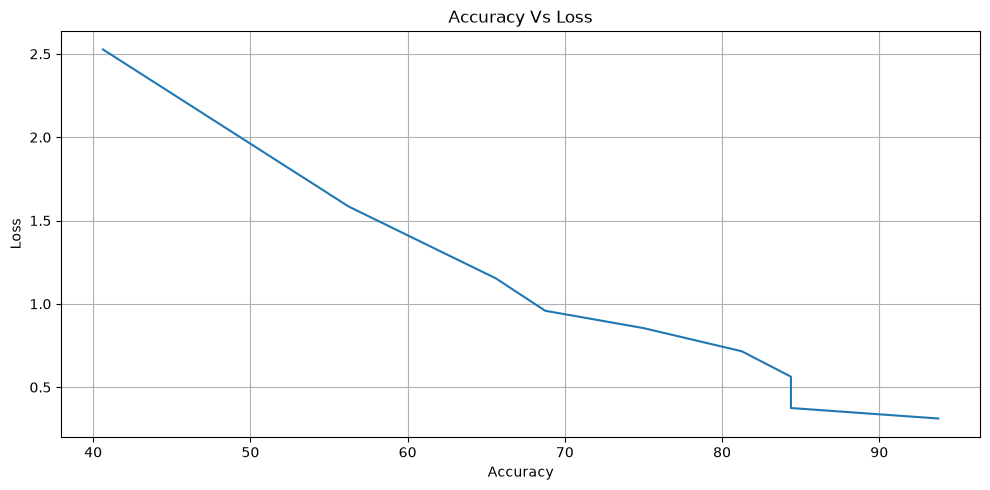

In [58]:
import matplotlib.pyplot as plt

loss = [2.5266, 1.5840, 1.1525, 0.9585, 0.8546,
        0.7156, 0.5631, 0.4525, 0.3749, 0.3121]

accuracy = [40.62, 56.25, 65.62, 68.75, 75.00,
            81.25, 84.38, 84.38, 84.38, 93.75]

plt.figure(figsize = (10 , 5))
plt.plot(accuracy, loss)
plt.xlabel("Accuracy")
plt.ylabel("Loss")
plt.title("Accuracy Vs Loss")

plt.grid(True)
plt.tight_layout()
plt.show()

In [59]:
epochs = 10

# Use test_loader from Cell 44 (which has normalized data)
optimizer = torch.optim.Adam(Sequential_layer.parameters(), lr=0.001)

for epoch in range(epochs):
    # --- Training Phase ---
    Sequential_layer.train()
    total_train_loss = 0.0
    total_train_samples = 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = Sequential_layer(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)
        total_train_samples += images.size(0)

    avg_train_loss = total_train_loss / total_train_samples

    # --- Validation Phase ---
    Sequential_layer.eval()
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in test_loader:  # Use test_loader!
            outputs = Sequential_layer(images)
            predicted = torch.argmax(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_accuracy = correct / total

    print(f"Epoch: {epoch + 1:2d} | Train Loss: {avg_train_loss:.4f} | Validation Accuracy: {val_accuracy:.4f}")


Epoch:  1 | Train Loss: 0.3772 | Validation Accuracy: 0.7212
Epoch:  2 | Train Loss: 0.3603 | Validation Accuracy: 0.7164
Epoch:  3 | Train Loss: 0.3563 | Validation Accuracy: 0.7188
Epoch:  4 | Train Loss: 0.3475 | Validation Accuracy: 0.7179
Epoch:  5 | Train Loss: 0.3423 | Validation Accuracy: 0.7199
Epoch:  6 | Train Loss: 0.3364 | Validation Accuracy: 0.7238
Epoch:  7 | Train Loss: 0.3268 | Validation Accuracy: 0.7178
Epoch:  8 | Train Loss: 0.3281 | Validation Accuracy: 0.7207
Epoch:  9 | Train Loss: 0.3203 | Validation Accuracy: 0.7184
Epoch: 10 | Train Loss: 0.3210 | Validation Accuracy: 0.7117


In [61]:
import torch
import json

MODEL_SAVE_PATH = "cifar10_cnn_model.pth"
torch.save(Sequential_layer.state_dict(), MODEL_SAVE_PATH)
print(f"✅ Model weights saved to: {MODEL_SAVE_PATH}")

CLASS_MAP_PATH= "class_to_idx.json"
with open(CLASS_MAP, "w") as f:
    json.dump(class_to_idx, f, indent=4)
print(f"✅ Class mapping saved to: {CLASS_MAP_PATH}")

✅ Model weights saved to: cifar10_cnn_model.pth
✅ Class mapping saved to: class_to_idx.json


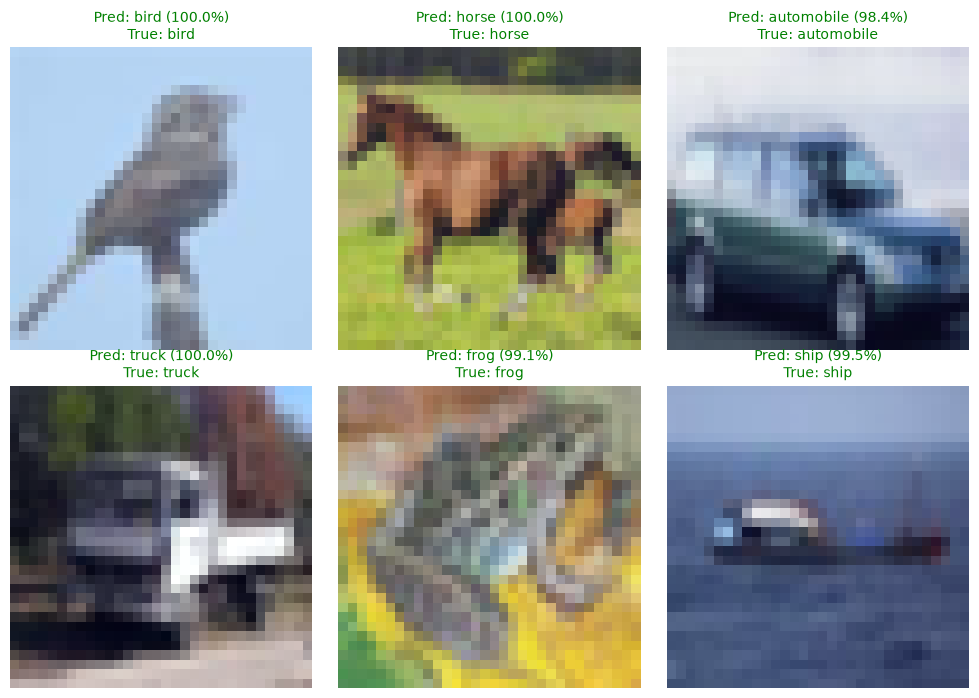

In [63]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

Sequential_layer.eval()

# Get one batch of test images
images, labels = next(iter(test_loader))
idx_to_class = {v: k for k, v in class_to_idx.items()}

with torch.inference_mode():
    outputs = Sequential_layer(images)
    probabilities = F.softmax(outputs, dim=1)
    confidences, predictions = torch.max(probabilities, dim=1)

# Plot first 6 predictions
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for i, ax in enumerate(axes.flat):
    # Unnormalize image for viewing: x * std + mean
    img = images[i].clone().permute(1, 2, 0).cpu().numpy()
    img = (img * 0.25) + 0.5
    img = img.clip(0, 1)

    true_name = idx_to_class[labels[i].item()]
    pred_name = idx_to_class[predictions[i].item()]
    conf = confidences[i].item() * 100

    color = "green" if true_name == pred_name else "red"
    ax.imshow(img)
    ax.set_title(f"Pred: {pred_name} ({conf:.1f}%)\nTrue: {true_name}", color=color, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


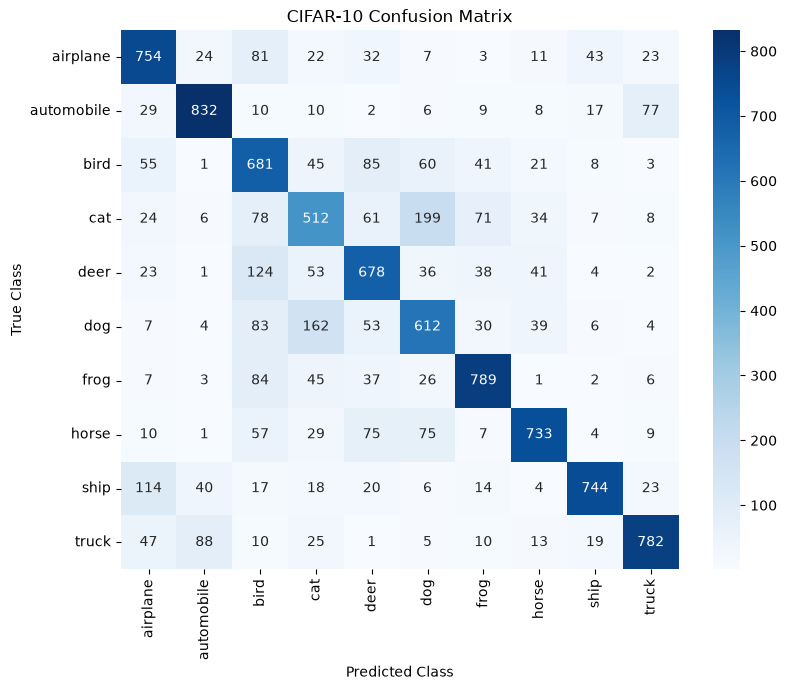

              precision    recall  f1-score   support

    airplane       0.70      0.75      0.73      1000
  automobile       0.83      0.83      0.83      1000
        bird       0.56      0.68      0.61      1000
         cat       0.56      0.51      0.53      1000
        deer       0.65      0.68      0.66      1000
         dog       0.59      0.61      0.60      1000
        frog       0.78      0.79      0.78      1000
       horse       0.81      0.73      0.77      1000
        ship       0.87      0.74      0.80      1000
       truck       0.83      0.78      0.81      1000

    accuracy                           0.71     10000
   macro avg       0.72      0.71      0.71     10000
weighted avg       0.72      0.71      0.71     10000



In [66]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

all_preds = []
all_labels = []

Sequential_layer.eval()
with torch.inference_mode():
    for imgs, lbls in test_loader:
        out = Sequential_layer(imgs)
        preds = torch.argmax(out, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(lbls.cpu().numpy())

class_names = [idx_to_class[i] for i in range(10)]

# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("CIFAR-10 Confusion Matrix")
plt.show()

# Print Precision, Recall, F1-Score
print(classification_report(all_labels, all_preds, target_names=class_names))
